# NeRF Evaluation

This notebook evaluates the reconstructed views produced by the simplified NeRF models for the synthetic **Lego** dataset, and the real **Poster** dataset.

The evaluation uses four image quality evaluation metrics:

- **MSE** — Mean Squared Error
- **PSNR** — Peak Signal to Noise Ratio
- **SSIM** — Structural Similarity Index
- **LPIPS** — Learned Perceptual Image Patch Similarity

## Setup

Device setup and initialization of the pretrained AlexNet LPIPS model.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import lpips

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity,
)

In [2]:
ROOT = Path.cwd()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Repository:", ROOT)
print("Device:", device)

# LPIPS using pretrained AlexNet
lpips_model = lpips.LPIPS(
    net="alex"
).to(device)

lpips_model.eval()

print("LPIPS loaded successfully.")

Repository: c:\Users\abdis\4030-Assignment-2
Device: cuda
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\abdis\miniconda3\envs\pytorch3d\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\abdis\miniconda3\envs\pytorch3d\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\abdis\miniconda3\envs\pytorch3d\lib\site-packages\lpips\weights\v0.1\alex.pth
LPIPS loaded successfully.


## Metric Implementation

The evaluation pipeline loads the saved NeRF predictions and ground-truth images, and calculates MSE, PSNR, SSIM and LPIPS for each test view.

- https://scikit-image.org/docs/stable/api/skimage.metrics.html#skimage.metrics.peak_signal_noise_ratio, MSE, PSNR, SSIM
- https://github.com/richzhang/PerceptualSimilarity/blob/master/test_network.py, LPIPS

In [3]:
def load_test_images(path):
    """
    Load saved NeRF predictions and corresponding ground-truth images.

    Expected NPZ structure:
        predictions: [N, H, W, 3]
        targets:     [N, H, W, 3]

    Expected pixel range:
        [0, 1]
    """

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Could not find: {path}"
        )

    data = np.load(path)

    print("NPZ keys:", data.files)

    if (
        "predictions" not in data.files
        or "targets" not in data.files
    ):
        raise KeyError(
            f"Expected 'predictions' and 'targets'. "
            f"Found: {data.files}"
        )

    predictions = data[
        "predictions"
    ].astype(np.float32)

    targets = data[
        "targets"
    ].astype(np.float32)

    if predictions.shape != targets.shape:
        raise ValueError(
            f"Prediction shape {predictions.shape} "
            f"does not match target shape {targets.shape}"
        )

    if (
        predictions.ndim != 4
        or predictions.shape[-1] != 3
    ):
        raise ValueError(
            "Expected image arrays with shape "
            f"[N, H, W, 3], got {predictions.shape}"
        )

    # protect metrics against small numerical values outside the expected image range
    predictions = np.clip(
        predictions,
        0.0,
        1.0
    )

    targets = np.clip(
        targets,
        0.0,
        1.0
    )

    print(f"Loaded: {path}")
    print(f"Number of images: {len(predictions)}")
    print(f"Shape: {predictions.shape}")

    return predictions, targets


def calculate_lpips(prediction, target):
    """
    Calculate LPIPS perceptual distance between
    two RGB images.

    Input:
        prediction: [H, W, 3], range [0, 1]
        target:     [H, W, 3], range [0, 1]

    LPIPS expects:
        [N, C, H, W], range [-1, 1]
    """

    pred_tensor = (
        torch.from_numpy(prediction)
        .permute(2, 0, 1)
        .unsqueeze(0)
        .float()
        .to(device)
    )

    target_tensor = (
        torch.from_numpy(target)
        .permute(2, 0, 1)
        .unsqueeze(0)
        .float()
        .to(device)
    )

    # converts [0, 1] to [-1, 1]
    pred_tensor = (
        pred_tensor * 2.0 - 1.0
    )

    target_tensor = (
        target_tensor * 2.0 - 1.0
    )

    with torch.no_grad():
        score = lpips_model(
            pred_tensor,
            target_tensor
        )

    return score.item()


def evaluate_images(predictions, targets):
    """
    Evaluate all held-out test images.

    Metrics:
        MSE    - lower is better
        PSNR   - higher is better
        SSIM   - higher is better
        LPIPS  - lower is better

    Returns:
        pandas DataFrame with one row per image.
    """

    results = []

    for i, (prediction, target) in enumerate(
        zip(predictions, targets)
    ):

        mse = mean_squared_error(
            target,
            prediction
        )

        psnr = peak_signal_noise_ratio(
            target,
            prediction,
            data_range=1.0
        )

        ssim = structural_similarity(
            target,
            prediction,
            channel_axis=-1,
            data_range=1.0
        )

        lpips_score = calculate_lpips(
            prediction,
            target
        )

        results.append(
            {
                "image": i,
                "MSE": mse,
                "PSNR": psnr,
                "SSIM": ssim,
                "LPIPS": lpips_score,
            }
        )

    return pd.DataFrame(results)


def summarize_metrics(results):
    """
    Return mean and standard deviation
    for all evaluation metrics.
    """

    return results[
        [
            "MSE",
            "PSNR",
            "SSIM",
            "LPIPS",
        ]
    ].agg(
        ["mean", "std"]
    )


print("Evaluation functions loaded.")

Evaluation functions loaded.


## Experiment Setup

Three saved Lego configurations and the Poster reconstruction are loaded for evaluation.

In [4]:
lego_experiments = {
    "Lego 200px / 10k": (
        ROOT
        / "lego_output_res200"
        / "lego_test_images.npz"
    ),

    "Lego 400px / 20k": (
        ROOT
        / "lego_output_res400"
        / "lego_test_images.npz"
    ),

    "Lego 400px / 40k / 192 pts": (
        ROOT
        / "lego_output_res400_40k_pts192"
        / "lego_test_images.npz"
    ),
}


poster_path = (
    ROOT
    / "poster_outputs"
    / "poster_test_images.npz"
)


print("Available Lego experiments:")

for name, path in lego_experiments.items():
    print(
        f"{name}: {path.exists()}"
    )


print()

print(
    "Poster test images:",
    poster_path.exists()
)

Available Lego experiments:
Lego 200px / 10k: True
Lego 400px / 20k: True
Lego 400px / 40k / 192 pts: True

Poster test images: True


In [5]:
lego_all_results = {}

lego_summary_rows = []


for experiment_name, experiment_path in lego_experiments.items():

    print()
    print("=" * 70)
    print(experiment_name)
    print("=" * 70)

    predictions, targets = load_test_images(
        experiment_path
    )

    metrics = evaluate_images(
        predictions,
        targets
    )

    lego_all_results[
        experiment_name
    ] = {
        "predictions": predictions,
        "targets": targets,
        "metrics": metrics,
    }

    lego_summary_rows.append(
        {
            "Experiment": experiment_name,
            "MSE": metrics["MSE"].mean(),
            "MSE std": metrics["MSE"].std(),
            "PSNR": metrics["PSNR"].mean(),
            "PSNR std": metrics["PSNR"].std(),
            "SSIM": metrics["SSIM"].mean(),
            "SSIM std": metrics["SSIM"].std(),
            "LPIPS": metrics["LPIPS"].mean(),
            "LPIPS std": metrics["LPIPS"].std(),
        }
    )


lego_summary = pd.DataFrame(
    lego_summary_rows
)

lego_summary


Lego 200px / 10k
NPZ keys: ['predictions', 'targets']
Loaded: c:\Users\abdis\4030-Assignment-2\lego_output_res200\lego_test_images.npz
Number of images: 20
Shape: (20, 200, 200, 3)

Lego 400px / 20k
NPZ keys: ['predictions', 'targets']
Loaded: c:\Users\abdis\4030-Assignment-2\lego_output_res400\lego_test_images.npz
Number of images: 20
Shape: (20, 400, 400, 3)

Lego 400px / 40k / 192 pts
NPZ keys: ['predictions', 'targets']
Loaded: c:\Users\abdis\4030-Assignment-2\lego_output_res400_40k_pts192\lego_test_images.npz
Number of images: 20
Shape: (20, 400, 400, 3)


,Experiment,MSE,MSE std,PSNR,PSNR std,SSIM,SSIM std,LPIPS,LPIPS std
0,Lego 200px / 10k,0.007426,0.001933,21.407792,0.982589,0.846828,0.011122,0.226166,0.032623
1,Lego 400px / 20k,0.006990,0.002047,21.698178,1.091236,0.850639,0.009349,0.160824,0.016294
2,Lego 400px / 40k / 192 pts,0.006406,0.002065,22.102969,1.178829,0.881641,0.009048,0.123578,0.014345


In [6]:
lego_configuration_table = lego_summary[
    [
        "Experiment",
        "MSE",
        "PSNR",
        "SSIM",
        "LPIPS",
    ]
]

display(
    lego_configuration_table.style.format(
        {
            "MSE": "{:.5f}",
            "PSNR": "{:.2f}",
            "SSIM": "{:.4f}",
            "LPIPS": "{:.4f}",
        }
    )
)

,Experiment,MSE,PSNR,SSIM,LPIPS
0,Lego 200px / 10k,0.00743,21.41,0.8468,0.2262
1,Lego 400px / 20k,0.00699,21.70,0.8506,0.1608
2,Lego 400px / 40k / 192 pts,0.00641,22.10,0.8816,0.1236


In [7]:
for _, row in lego_summary.iterrows():

    print(
        row["Experiment"]
    )

    print(
        f"  MSE:   "
        f"{row['MSE']:.5f} ± "
        f"{row['MSE std']:.5f}"
    )

    print(
        f"  PSNR:  "
        f"{row['PSNR']:.2f} ± "
        f"{row['PSNR std']:.2f} dB"
    )

    print(
        f"  SSIM:  "
        f"{row['SSIM']:.4f} ± "
        f"{row['SSIM std']:.4f}"
    )

    print(
        f"  LPIPS: "
        f"{row['LPIPS']:.4f} ± "
        f"{row['LPIPS std']:.4f}"
    )

    print()

Lego 200px / 10k
  MSE:   0.00743 ± 0.00193
  PSNR:  21.41 ± 0.98 dB
  SSIM:  0.8468 ± 0.0111
  LPIPS: 0.2262 ± 0.0326

Lego 400px / 20k
  MSE:   0.00699 ± 0.00205
  PSNR:  21.70 ± 1.09 dB
  SSIM:  0.8506 ± 0.0093
  LPIPS: 0.1608 ± 0.0163

Lego 400px / 40k / 192 pts
  MSE:   0.00641 ± 0.00207
  PSNR:  22.10 ± 1.18 dB
  SSIM:  0.8816 ± 0.0090
  LPIPS: 0.1236 ± 0.0143



## Graphing

PSNR, SSIM and LPIPS are plotted across the Lego configurations.

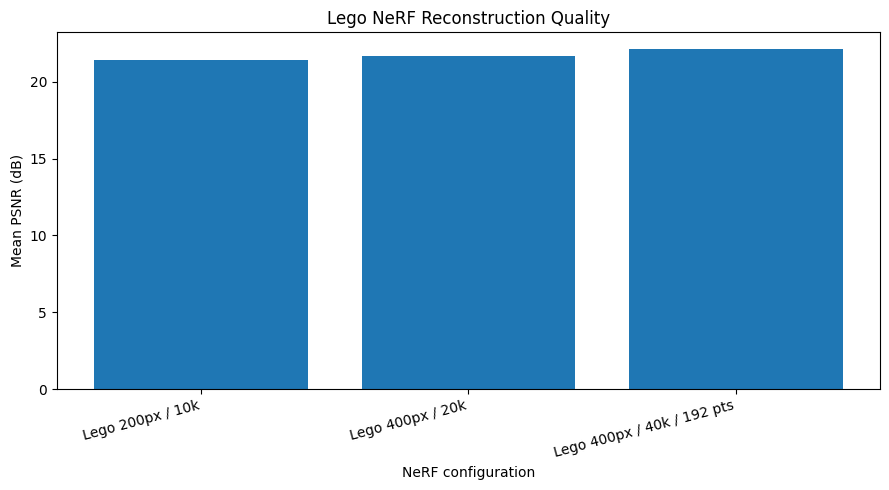

In [8]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["PSNR"]
)

plt.ylabel(
    "Mean PSNR (dB)"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Reconstruction Quality"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.show()

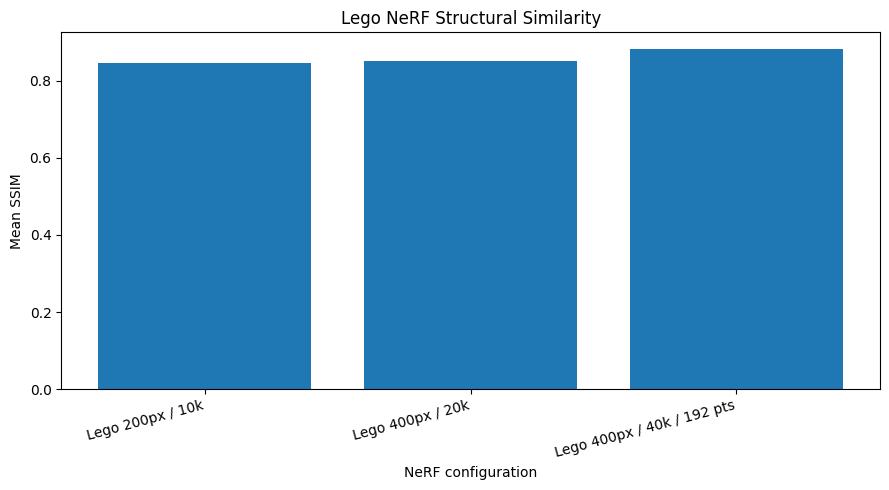

In [9]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["SSIM"]
)

plt.ylabel(
    "Mean SSIM"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Structural Similarity"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.show()

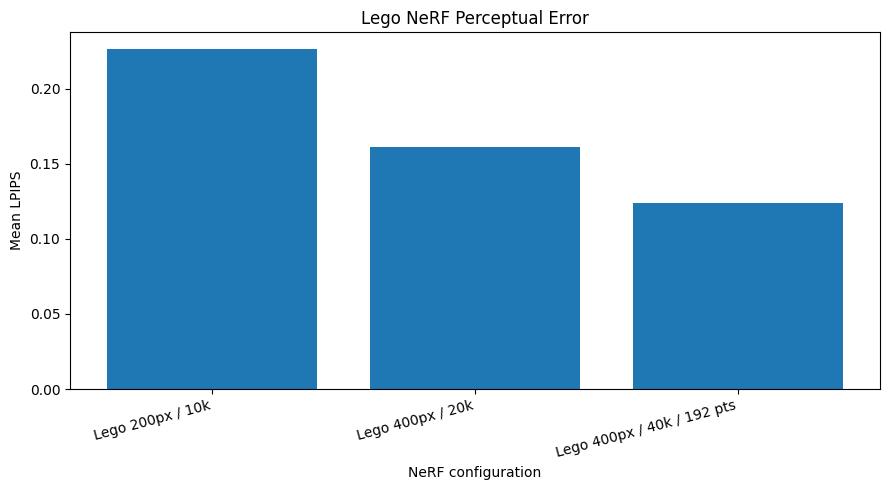

In [10]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["LPIPS"]
)

plt.ylabel(
    "Mean LPIPS"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Perceptual Error"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.show()

## Poster Evaluation

The same metric pipeline is used on the Poster dataset.

In [11]:
poster_results = None
poster_predictions = None
poster_targets = None


if poster_path.exists():

    print("=" * 70)
    print("Poster evaluation")
    print("=" * 70)

    poster_predictions, poster_targets = load_test_images(
        poster_path
    )

    poster_results = evaluate_images(
        poster_predictions,
        poster_targets
    )

    display(
        poster_results
    )

else:

    print(
        "Poster evaluation cannot run yet."
    )

    print(
        "Missing file:"
    )

    print(
        poster_path
    )

    print()

    print(
        "The Poster notebook must export "
        "poster_test_images.npz containing "
        "'predictions' and 'targets'."
    )

Poster evaluation
NPZ keys: ['predictions', 'targets', 'frame_ids']
Loaded: c:\Users\abdis\4030-Assignment-2\poster_outputs\poster_test_images.npz
Number of images: 23
Shape: (23, 1920, 1080, 3)


,image,MSE,PSNR,SSIM,LPIPS
0,0,0.002855,25.443362,0.872813,0.443161
1,1,0.002625,25.809150,0.880076,0.386217
2,2,0.001623,27.897876,0.895871,0.400787
3,3,0.002819,25.499333,0.869827,0.450986
4,4,0.003285,24.834432,0.861178,0.441733
5,5,0.003076,25.119913,0.876328,0.384242
6,6,0.003385,24.704660,0.856871,0.459750
7,7,0.003080,25.113834,0.862828,0.423333
8,8,0.002977,25.262331,0.816958,0.510417
9,9,0.005015,22.997210,0.746001,0.615688


In [12]:
if poster_results is not None:

    poster_summary = summarize_metrics(
        poster_results
    )

    display(
        poster_summary
    )

    print("POSTER RESULTS")
    print("-" * 40)

    print(
        f"MSE:   "
        f"{poster_results['MSE'].mean():.5f} ± "
        f"{poster_results['MSE'].std():.5f}"
    )

    print(
        f"PSNR:  "
        f"{poster_results['PSNR'].mean():.2f} ± "
        f"{poster_results['PSNR'].std():.2f} dB"
    )

    print(
        f"SSIM:  "
        f"{poster_results['SSIM'].mean():.4f} ± "
        f"{poster_results['SSIM'].std():.4f}"
    )

    print(
        f"LPIPS: "
        f"{poster_results['LPIPS'].mean():.4f} ± "
        f"{poster_results['LPIPS'].std():.4f}"
    )

else:

    print(
        "Poster results unavailable."
    )

,MSE,PSNR,SSIM,LPIPS
mean,0.002997,25.363012,0.851842,0.480311
std,0.000754,1.093334,0.034575,0.060463


POSTER RESULTS
----------------------------------------
MSE:   0.00300 ± 0.00075
PSNR:  25.36 ± 1.09 dB
SSIM:  0.8518 ± 0.0346
LPIPS: 0.4803 ± 0.0605


## Dataset Comparison

The best Lego configuration is selected for comparison with the Poster reconstruction.

In [13]:
BEST_LEGO = (
    "Lego 400px / 40k / 192 pts"
)


lego_predictions = (
    lego_all_results[
        BEST_LEGO
    ]["predictions"]
)

lego_targets = (
    lego_all_results[
        BEST_LEGO
    ]["targets"]
)

lego_results = (
    lego_all_results[
        BEST_LEGO
    ]["metrics"]
)


print(
    "Selected final Lego model:",
    BEST_LEGO
)

Selected final Lego model: Lego 400px / 40k / 192 pts


In [14]:
dataset_rows = [
    {
        "Dataset": "Synthetic Lego",

        "MSE":
            lego_results["MSE"].mean(),

        "PSNR":
            lego_results["PSNR"].mean(),

        "SSIM":
            lego_results["SSIM"].mean(),

        "LPIPS":
            lego_results["LPIPS"].mean(),
    }
]


if poster_results is not None:

    dataset_rows.append(
        {
            "Dataset": "Real Poster",

            "MSE":
                poster_results["MSE"].mean(),

            "PSNR":
                poster_results["PSNR"].mean(),

            "SSIM":
                poster_results["SSIM"].mean(),

            "LPIPS":
                poster_results["LPIPS"].mean(),
        }
    )


dataset_comparison = pd.DataFrame(
    dataset_rows
)


display(
    dataset_comparison.style.format(
        {
            "MSE": "{:.5f}",
            "PSNR": "{:.2f}",
            "SSIM": "{:.4f}",
            "LPIPS": "{:.4f}",
        }
    )
)

,Dataset,MSE,PSNR,SSIM,LPIPS
0,Synthetic Lego,0.00641,22.10,0.8816,0.1236
1,Real Poster,0.00300,25.36,0.8518,0.4803


## Qualitative Evaluation

Best and worst test views are compared with ground truth and visualized with error maps.

In [15]:
lego_best_idx = (
    lego_results["PSNR"].idxmax()
)

lego_worst_idx = (
    lego_results["PSNR"].idxmin()
)


print(
    f"Best Lego view: "
    f"{lego_best_idx}"
)

print(
    f"PSNR: "
    f"{lego_results.loc[lego_best_idx, 'PSNR']:.2f} dB"
)

print()

print(
    f"Worst Lego view: "
    f"{lego_worst_idx}"
)

print(
    f"PSNR: "
    f"{lego_results.loc[lego_worst_idx, 'PSNR']:.2f} dB"
)

Best Lego view: 6
PSNR: 23.72 dB

Worst Lego view: 9
PSNR: 19.15 dB


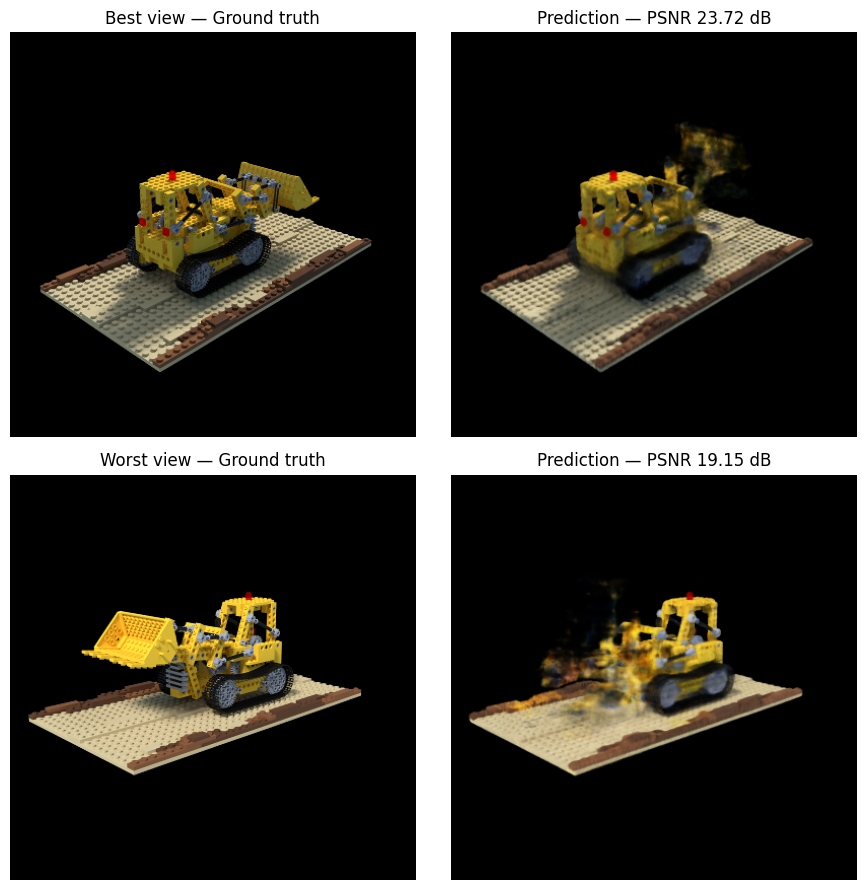

In [16]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(9, 9)
)


# best ground truth
axes[0, 0].imshow(
    lego_targets[
        lego_best_idx
    ]
)

axes[0, 0].set_title(
    "Best view — Ground truth"
)


# best prediction
axes[0, 1].imshow(
    lego_predictions[
        lego_best_idx
    ]
)

axes[0, 1].set_title(
    f"Prediction — "
    f"PSNR "
    f"{lego_results.loc[lego_best_idx, 'PSNR']:.2f} dB"
)


# worst ground truth
axes[1, 0].imshow(
    lego_targets[
        lego_worst_idx
    ]
)

axes[1, 0].set_title(
    "Worst view — Ground truth"
)


# worst prediction
axes[1, 1].imshow(
    lego_predictions[
        lego_worst_idx
    ]
)

axes[1, 1].set_title(
    f"Prediction — "
    f"PSNR "
    f"{lego_results.loc[lego_worst_idx, 'PSNR']:.2f} dB"
)


for ax in axes.ravel():
    ax.axis("off")


plt.tight_layout()

plt.show()

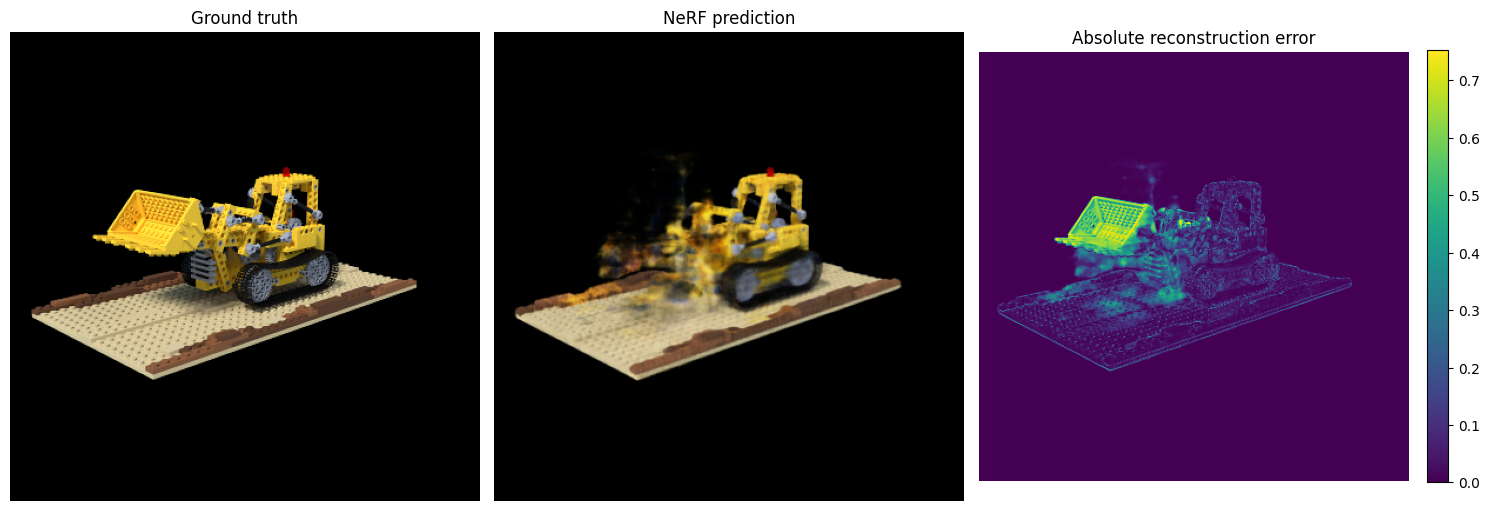

In [17]:
idx = lego_worst_idx


prediction = (
    lego_predictions[idx]
)

target = (
    lego_targets[idx]
)


absolute_error = np.abs(
    prediction - target
)


error_map = absolute_error.mean(
    axis=-1
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].imshow(
    target
)

axes[0].set_title(
    "Ground truth"
)


axes[1].imshow(
    prediction
)

axes[1].set_title(
    "NeRF prediction"
)


im = axes[2].imshow(
    error_map
)

axes[2].set_title(
    "Absolute reconstruction error"
)


for ax in axes:
    ax.axis("off")


plt.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)


plt.tight_layout()

plt.show()

In [18]:
poster_best_idx = None
poster_worst_idx = None


if poster_results is not None:

    poster_best_idx = (
        poster_results["PSNR"].idxmax()
    )

    poster_worst_idx = (
        poster_results["PSNR"].idxmin()
    )

    print(
        f"Best Poster view: "
        f"{poster_best_idx}"
    )

    print(
        f"PSNR: "
        f"{poster_results.loc[poster_best_idx, 'PSNR']:.2f} dB"
    )

    print()

    print(
        f"Worst Poster view: "
        f"{poster_worst_idx}"
    )

    print(
        f"PSNR: "
        f"{poster_results.loc[poster_worst_idx, 'PSNR']:.2f} dB"
    )

else:

    print(
        "Poster results unavailable."
    )

Best Poster view: 2
PSNR: 27.90 dB

Worst Poster view: 9
PSNR: 23.00 dB


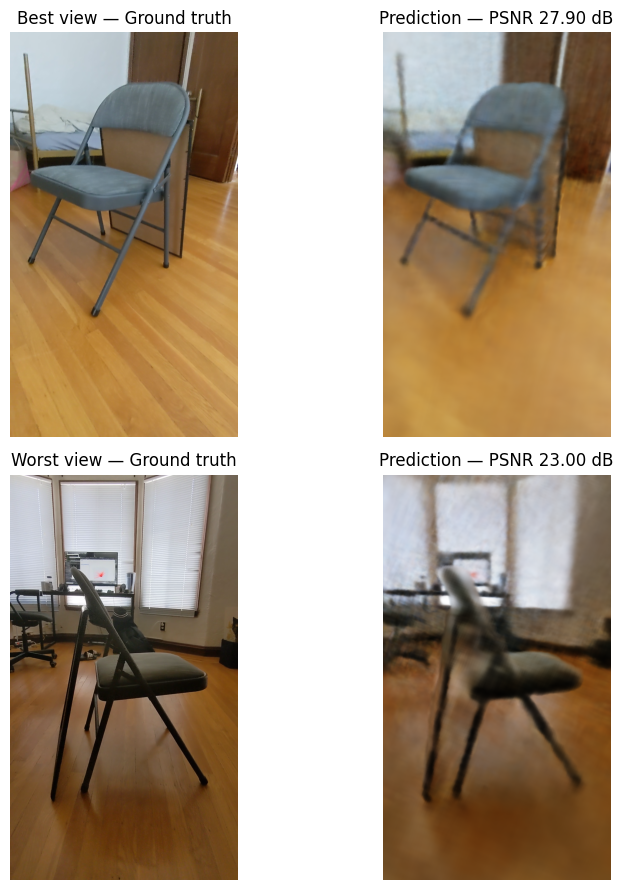

In [19]:
if poster_results is not None:

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(9, 9)
    )


    axes[0, 0].imshow(
        poster_targets[
            poster_best_idx
        ]
    )

    axes[0, 0].set_title(
        "Best view — Ground truth"
    )


    axes[0, 1].imshow(
        poster_predictions[
            poster_best_idx
        ]
    )

    axes[0, 1].set_title(
        f"Prediction — "
        f"PSNR "
        f"{poster_results.loc[poster_best_idx, 'PSNR']:.2f} dB"
    )


    axes[1, 0].imshow(
        poster_targets[
            poster_worst_idx
        ]
    )

    axes[1, 0].set_title(
        "Worst view — Ground truth"
    )


    axes[1, 1].imshow(
        poster_predictions[
            poster_worst_idx
        ]
    )

    axes[1, 1].set_title(
        f"Prediction — "
        f"PSNR "
        f"{poster_results.loc[poster_worst_idx, 'PSNR']:.2f} dB"
    )


    for ax in axes.ravel():
        ax.axis("off")


    plt.tight_layout()

    plt.show()

else:

    print(
        "Poster results unavailable."
    )

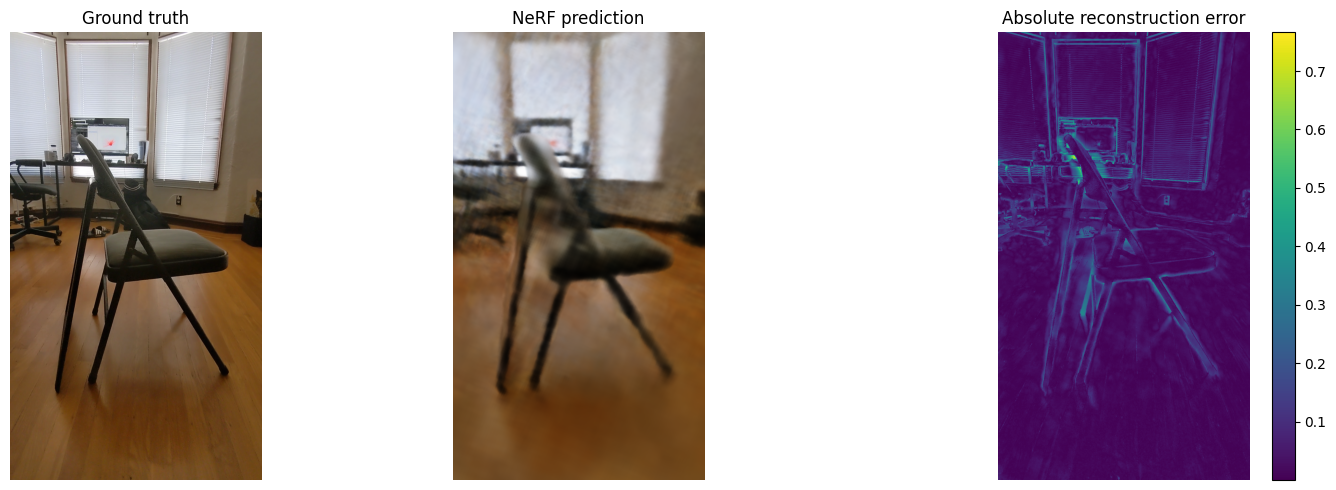

In [20]:
if poster_results is not None:

    idx = poster_worst_idx


    prediction = (
        poster_predictions[idx]
    )

    target = (
        poster_targets[idx]
    )


    absolute_error = np.abs(
        prediction - target
    )


    error_map = absolute_error.mean(
        axis=-1
    )


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )


    axes[0].imshow(
        target
    )

    axes[0].set_title(
        "Ground truth"
    )


    axes[1].imshow(
        prediction
    )

    axes[1].set_title(
        "NeRF prediction"
    )


    im = axes[2].imshow(
        error_map
    )

    axes[2].set_title(
        "Absolute reconstruction error"
    )


    for ax in axes:
        ax.axis("off")


    plt.colorbar(
        im,
        ax=axes[2],
        fraction=0.046,
        pad=0.04
    )


    plt.tight_layout()

    plt.show()

else:

    print(
        "Poster results unavailable."
    )

## Export Results

Numerical results and figures are saved for use in the report.

In [21]:
RESULTS_DIR = (
    ROOT
    / "evaluation_results"
)


RESULTS_DIR.mkdir(
    exist_ok=True
)


# lego configuration comparison
lego_summary.to_csv(
    RESULTS_DIR
    / "lego_configuration_summary.csv",
    index=False
)


# per view results for final lego model
lego_results.to_csv(
    RESULTS_DIR
    / "lego_best_per_view.csv",
    index=False
)


# lego vs poster
dataset_comparison.to_csv(
    RESULTS_DIR
    / "dataset_comparison.csv",
    index=False
)


# Poster per view metrics
if poster_results is not None:

    poster_results.to_csv(
        RESULTS_DIR
        / "poster_per_view.csv",
        index=False
    )


print(
    "Evaluation results saved to:"
)

print(
    RESULTS_DIR
)

Evaluation results saved to:
c:\Users\abdis\4030-Assignment-2\evaluation_results


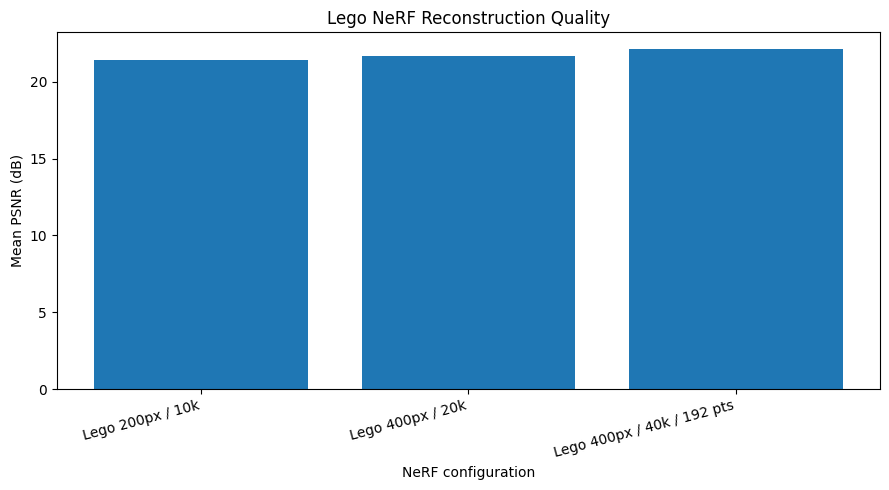

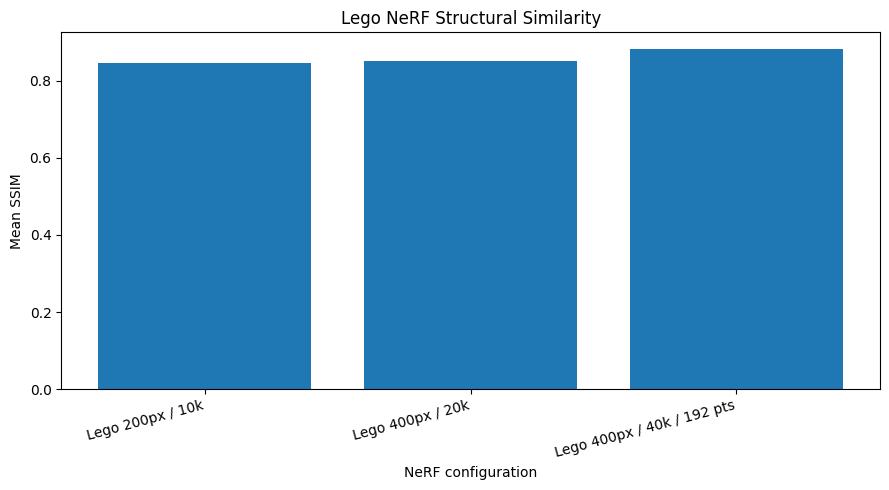

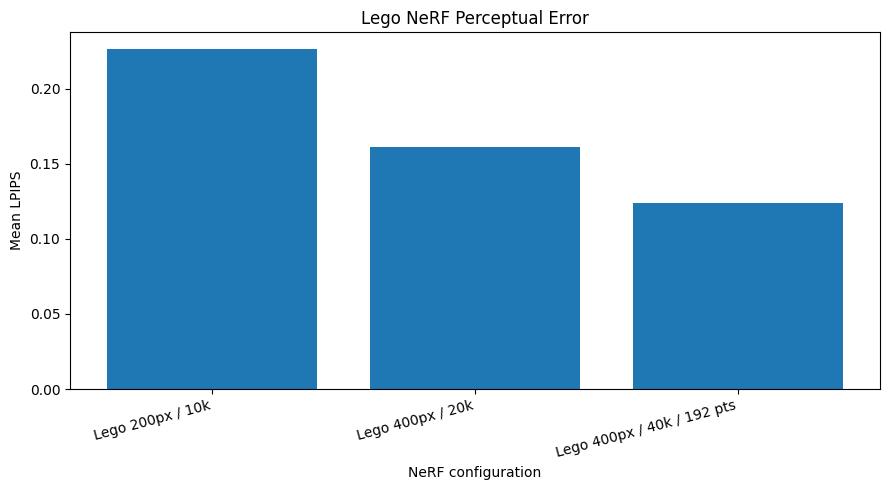

In [22]:
# PSNR plot
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["PSNR"]
)

plt.ylabel(
    "Mean PSNR (dB)"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Reconstruction Quality"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "lego_psnr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SSIM plot
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["SSIM"]
)

plt.ylabel(
    "Mean SSIM"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Structural Similarity"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "lego_ssim_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# LPIPS plot
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    lego_summary["Experiment"],
    lego_summary["LPIPS"]
)

plt.ylabel(
    "Mean LPIPS"
)

plt.xlabel(
    "NeRF configuration"
)

plt.title(
    "Lego NeRF Perceptual Error"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "lego_lpips_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()